# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [54]:
import pandas as pd

# Cambia `user_profile` por el DataFrame original que quieras revisar (ej. users, usage o user_profile)
df_rev = user_profile
total_filas = len(df_rev)

# 1. Valores nulos por columna (cantidad y %)
nulos = df_rev.isna().sum()
nulos_df = pd.DataFrame({
    "nulos_filas": nulos,
    "porcentaje (%)": (nulos / total_filas * 100).round(2),
})
print("--- VALORES NULOS ---")
print(nulos_df[nulos_df["nulos_filas"] > 0])

# 2. Filas duplicadas (cantidad y %)
duplicados = df_rev.duplicated().sum()
print("\n--- DUPLICADOS ---")
print(
    f"Filas duplicadas: {duplicados} ({duplicados / total_filas * 100:.2f}%)"
    f" de {total_filas}"
)

# 3. Revisión rápida de valores fuera de rango o negativos en columnas numéricas
print("\n--- MÍNIMOS / MÁXIMOS NUMÉRICOS ---")
print(df_rev.describe().T[["min", "50%", "max"]])

--- VALORES NULOS ---
            nulos_filas  porcentaje (%)
city                565           14.12
reg_date             40            1.00
churn_date         3534           88.35

--- DUPLICADOS ---
Filas duplicadas: 0 (0.00%) de 4000

--- MÍNIMOS / MÁXIMOS NUMÉRICOS ---
                          min       50%       max
user_id               10000.0  11999.50  13999.00
age                      18.0     48.00     79.00
cant_mensajes             0.0      5.00     17.00
cant_llamadas             0.0      4.00     15.00
cant_minutos_llamada      0.0     19.78    155.69


In [2]:

plans = pd.read_csv("/datasets/plans.csv")
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

# resumen completo de columnas, tipos de datos y valores no nulos
plans.info()
users.info()
usage.info()

plans (2, 8)
users (4000, 8)
usage (40000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 

In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())

print("\nProporción de valores nulos:")
print(users.isna().mean())

Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:")
print(usage.isna().sum())

print("\nProporción de valores nulos:")
print(usage.isna().mean())

Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  
plans: ninguna columna tiene valores nulos (0%).
users: city tiene 469 nulos (11.72%) y churn_date tiene 3,534 nulos (88.35%); el resto de columnas tienen 0.00%.
usage: date tiene 50 nulos (0.12%), duration tiene 22,076 nulos (55.19%) y length tiene 17,896 nulos (44.74%); el resto de columnas tienen 0.00%.
- Indica qué harías: ¿imputar, eliminar, ignorar?

city (users, 11.72%): Investigar para imputar o dejar como nulos — revisaría si la ciudad se puede inferir por usuario/región o dejar como nulo si no aporta al análisis sin sesgar.
churn_date (users, 88.35%): Ignorar o dejar como nulos (con precaución) — su alta proporción de ausentes suele indicar usuarios aún activos, por lo que conviene tratarlo con cuidado y no imputar fechas artificiales.
date (usage, 0.12%): Dejar como nulos o imputar con cautela — al ser una proporción mínima (0.12%), el impacto es bajo y no conviene inventar fechas exactas de uso.
duration (usage, 55.19%): Investigar antes de decidir (dejar como nulos o revisar según type) — conviene comprobar si los nulos corresponden a eventos que no tienen duración (como mensajes o datos), evitando imputaciones que distorsionen promedios.
length (usage, 44.74%): Investigar antes de decidir (dejar como nulos o revisar según type) — vale la pena verificar si depende del tipo de registro/evento antes de dejar los nulos o aplicar alguna regla específica.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:


# explorar columnas numéricas de users
print(users.describe())



            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [13]:

# explorar columnas numéricas de usage
print(users.describe())


            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000



Columnas numéricas
id y user_id: rangos ordenados (user_id de 10000 a 13999 en users y usage; id de 1 a 40000 en usage), sin negativos ni sentinels evidentes.
age (users): cuartiles normales (32, 47, 63) y máximo 79, pero tiene un sentinel en min = -999.0.
duration y length (usage): ambas parten de 0.0 (sin negativos); duration llega hasta 120.0 (mediana 3.50) y length hasta 1490.0 (mediana 50.0), con valores altos que conviene revisar.

Columnas categóricas

type (usage): limpia, solo text (22,092) y call (17,908).
city (users): ciudades válidas (Bogotá, CDMX, Medellín, GDL, Cali, MTY), 469 NaN y el sentinel ? (96 registros).
plan (users): limpia, solo Basico (2,595) y Premium (1,405).



In [14]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"--- {col} ---")
    print(users[col].value_counts(dropna=False))

--- city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
--- plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



-La columna city: presenta ciudades válidas (Bogotá con 808, CDMX con 730, Medellín con 616, GDL con 450, Cali con 424 y MTY con 407), 469 valores nulos (NaN) y un valor sentinel ? (96 registros) que representa datos faltantes o inválidos en texto.

-La columna plan: contiene únicamente dos categorías (Basico con 2,595 registros y Premium con 1,405), sin valores nulos ni sentinels (solo con Basico escrito sin tilde).

In [15]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

La columna type: contiene únicamente dos categorías válidas, text (22,092 registros) y call (17,908 registros), sin valores nulos (NaN) ni sentinels o etiquetas anómalas.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  

¿En qué columnas encontraste valores inválidos o sentinels?

-age (users): presenta el valor sentinel -999.0 como mínimo, un valor imposible para una edad que distorsiona estadísticos como la media y la desviación estándar.
-city (users): contiene ? (96 registros), que actúa como un sentinel de texto para datos faltantes o no registrados.

¿Qué acción tomarías?
-En age (users): reemplazar -999 por NaN (valor faltante estándar) para que no altere cálculos numéricos ni promedios, y luego decidir el tratamiento de esos faltantes según el análisis.
-En city (users): estandarizar '?' a NaN para unificarlo con los nulos existentes (469 NaN) y evitar que cuente como una ciudad real.
-En duration y length (usage): verificar primero si los ceros y los valores máximos (120.0 y 1490.0) corresponden a casos válidos del negocio o a errores de registro antes de filtrar o imputar.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:


# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')



In [17]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [18]:


# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()



2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En reg_date, los registros se concentran principalmente entre 2022 (1,314), 2023 (1,316) y 2024 (1,330), sin valores NaN (NaT) en el conteo, pero aparece 2026 con 40 registros, lo cual queda posterior a 2024 (fuera del rango esperado si los datos llegan hasta 2024) y conviene revisar o depurar según el criterio de limpieza del proyecto.

In [20]:

# Revisar los años presentes en date de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64

En date, la gran mayoría de los registros corresponden al año 2024 (39,950 filas, mostradas como 2024.0 por el tipo numérico con nulos), y aparecen 50 valores NaN (fechas faltantes o no parseables), sin años negativos, anteriores a 1900 ni posteriores a 2024; dado que el análisis se basará en estas fechas, conviene tener presentes esos 50 registros sin fecha al filtrar o analizar la actividad temporal.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  

- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

En users['reg_date']: no aparecen años negativos ni extremadamente antiguos (como 1900 o menores), y la mayoría de los registros están en 2022 (1,314), 2023 (1,316) y 2024 (1,330). Sin embargo, sí aparece 2026 con 40 registros, lo cual queda posterior a 2024 (fuera del rango esperado si el corte de los datos llega hasta 2024).

En usage['date']: no aparecen años negativos, anteriores a 1900 ni posteriores a 2024; los registros con fecha válida corresponden únicamente a 2024 (39,950 filas, mostradas como 2024.0), y aparecen 50 valores NaN (fechas faltantes o que no se pudieron parsear).

- ¿Qué harías con ellas?

Para los 40 registros de 2026 en users['reg_date']: inspeccionar primero si se trata de un error de digitación/formato (por ejemplo, un año mal capturado) o de registros fuera del periodo válido del dataset; según el criterio de limpieza definido para el proyecto, convertir esos valores a NaT (NaN de fecha) o excluirlos del análisis temporal para que no distorsionen cohortes ni antigüedad de registro hasta 2024.

Para los 50 valores NaN en usage['date']: mantenerlos identificados como fechas faltantes (o excluirlos únicamente en análisis de series de tiempo / tendencias por fecha) sin inventar fechas, y verificar si al cruzar con users se conserva el resto de la información de uso cuando no dependa de la fecha.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:



# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()



count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [25]:

# Marcar fechas futuras como NaT para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [26]:
# Verificación MAR en usage (Missing At Random) para duration según type
usage.groupby('type', dropna=False)['duration'].agg(
    total_registros='size',
    nulos_duration=lambda s: s.isna().sum(),
    pct_nulos_duration=lambda s: round(s.isna().mean() * 100, 2)
)

,total_registros,nulos_duration,pct_nulos_duration
type,,,
call,17908,0.0,0.00
text,22092,22076.0,99.93


In [27]:
# Verificación MAR en usage (Missing At Random) para length según type
usage.groupby('type', dropna=False)['length'].agg(
    total_registros='size',
    nulos_length=lambda s: s.isna().sum(),
    pct_nulos_length=lambda s: round(s.isna().mean() * 100, 2)
)

,total_registros,nulos_length,pct_nulos_length
type,,,
call,17908,17896.0,99.93
text,22092,0.0,0.00


Diagnóstico de valores nulos en duration y length:
Los valores nulos en duration y length siguen un patrón MAR (Missing At Random) explicado por el tipo de evento (type): duration es nulo en el 99.93% (22,076 de 22,092) de los registros text y 0.00% en call, mientras que length es nulo en el 99.93% (17,896 de 17,908) de los registros call y 0.00% en text.

Decisión y justificación:
Se dejan como nulos (NaN) sin imputarlos con 0 ni eliminar filas. Rellenar con 0 en duration simularía llamadas de duración nula en eventos que son mensajes y sesgaría hacia abajo los promedios de duración; rellenar con 0 en length simularía mensajes vacíos en eventos que son llamadas y distorsionaría las métricas de longitud de texto. Mantenerlos como NaN preserva las 40,000 filas y permite calcular métricas limpias segmentando por type.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [31]:
# 1. Crear columnas auxiliares en usage
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Verificar que ya están creadas
print(usage.columns.tolist())

# 2. Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id", as_index=False)
    .agg({
        "is_text": "sum",
        "is_call": "sum",
        "duration": "sum",
    })
    .rename(columns={
        "is_text": "cant_mensajes",
        "is_call": "cant_llamadas",
        "duration": "cant_minutos_llamada",
    })
)

# Observar resultado
usage_agg.head(3)


['id', 'user_id', 'type', 'date', 'duration', 'length', 'is_text', 'is_call']


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [32]:
# Renombrar columnas
usage_agg = usage_agg.rename(
    columns={
        "is_text": "cant_mensajes",
        "is_call": "cant_llamadas",
        "duration": "cant_minutos_llamada",
    }
)

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Rellenar con 0 a los usuarios sin actividad registrada en usage
cols_uso = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

# Convertir conteos a enteros si quedaron como float tras el left join
user_profile[["cant_mensajes", "cant_llamadas"]] = user_profile[
    ["cant_mensajes", "cant_llamadas"]
].astype(int)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
cols_num = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

resumen_num = user_profile[cols_num].describe().T
resumen_num["mediana"] = user_profile[cols_num].median()

# Reordenar columnas para tener la mediana junto a la media
cols_orden = ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
resumen_num = resumen_num[cols_orden]
resumen_num

,count,mean,mediana,std,min,25%,50%,75%,max
age,4000.0,48.136000,48.00,17.689919,18.0,33.0000,48.00,63.0000,79.00
cant_mensajes,4000.0,5.523000,5.00,2.359738,0.0,4.0000,5.00,7.0000,17.00
cant_llamadas,4000.0,4.477000,4.00,2.145139,0.0,3.0000,4.00,6.0000,15.00
cant_minutos_llamada,4000.0,23.311225,19.78,18.169564,0.0,11.1075,19.78,31.4125,155.69


In [35]:
# Distribución porcentual del tipo de plan
dist_plan = pd.DataFrame({
    "total_usuarios": user_profile["plan"].value_counts(dropna=False),
    "porcentaje": (
        user_profile["plan"].value_counts(normalize=True, dropna=False) * 100
    ).round(2),
})

dist_plan


,total_usuarios,porcentaje
Basico,2595,64.88
Premium,1405,35.12


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

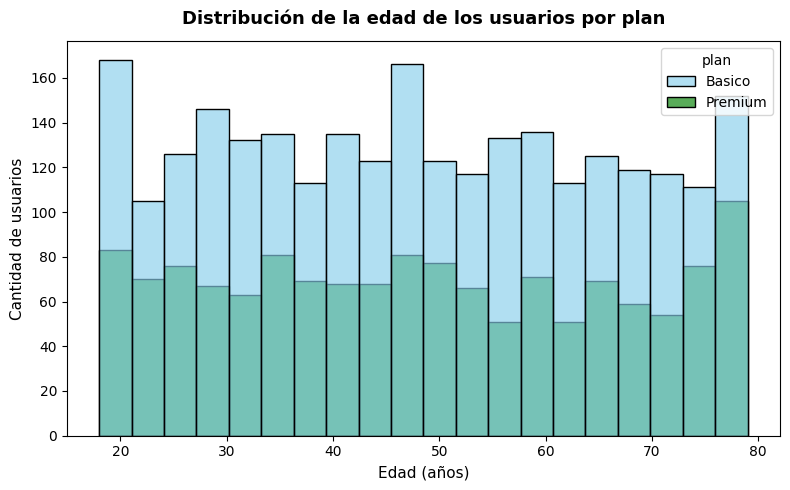

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))
ax = sns.histplot(
    data=user_profile,
    x="age",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=20,
    alpha=0.65,
)

ax.set_title("Distribución de la edad de los usuarios por plan", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Edad (años)", fontsize=11)
ax.set_ylabel("Cantidad de usuarios", fontsize=11)

plt.tight_layout()
plt.show()

💡Insights: 
age y plan: La edad de los usuarios presenta una distribución aproximadamente uniforme (sin sesgo pronunciado) entre los 18 y 79 años, con ligeros repuntes cerca de los 18–21, 46–49 y 76–79 años. Tanto en el plan Básico como en el Premium la edad se reparte a lo largo de todo el rango etario, manteniendo el plan Básico un mayor volumen en cada tramo acorde a su mayor peso en la base de clientes.

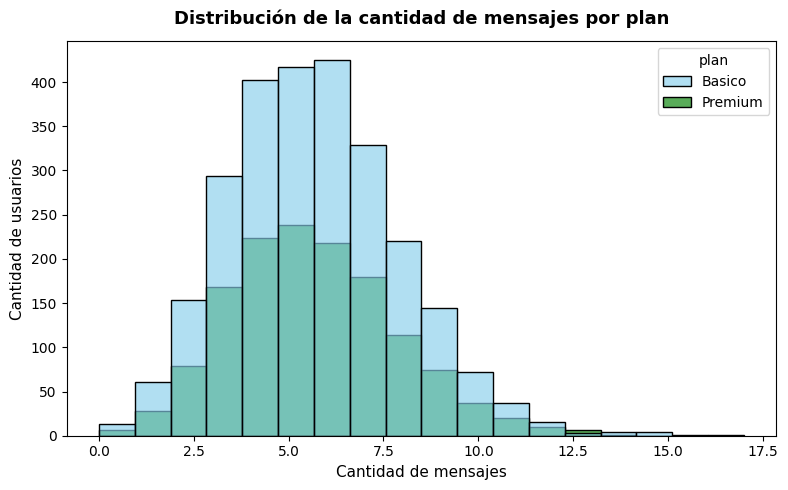

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
ax = sns.histplot(
    data=user_profile,
    x="cant_mensajes",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=18,
    alpha=0.65,
)

ax.set_title("Distribución de la cantidad de mensajes por plan", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Cantidad de mensajes", fontsize=11)
ax.set_ylabel("Cantidad de usuarios", fontsize=11)

plt.tight_layout()
plt.show()

💡Insights: 
cant_mensajes y plan: La distribución de cant_mensajes presenta un ligero sesgo a la derecha, con la mayoría de los usuarios concentrados entre 3 y 8 mensajes (mediana de 5.00 y media de 5.52) y una cola que se extiende hasta un máximo de 17 mensajes. Tanto los usuarios Básico como Premium muestran un comportamiento similar en la forma de su distribución, variando principalmente en altura por la mayor proporción de usuarios del plan Básico en la base.

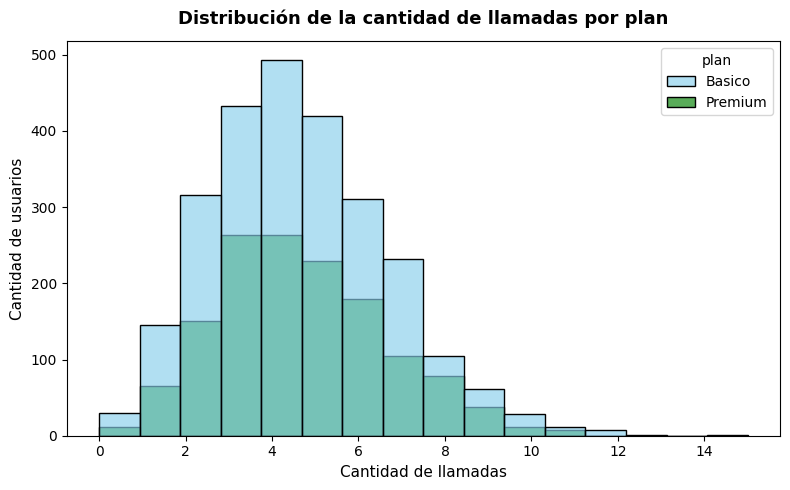

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
ax = sns.histplot(
    data=user_profile,
    x="cant_llamadas",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=16,
    alpha=0.65,
)

ax.set_title("Distribución de la cantidad de llamadas por plan", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Cantidad de llamadas", fontsize=11)
ax.set_ylabel("Cantidad de usuarios", fontsize=11)

plt.tight_layout()
plt.show()

💡Insights: 
cant_llamadas y plan: La variable cant_llamadas presenta una distribución sesgada a la derecha, concentrando a la gran mayoría de los clientes entre 2 y 6 llamadas por periodo (mediana de 4.00 y media de 4.48) y alargándose en una cola hasta las 15 llamadas. El comportamiento de los usuarios Básico y Premium es prácticamente homólogo en forma; la diferencia en la altura de las barras responde únicamente a la mayor presencia del plan Básico en la base de datos.

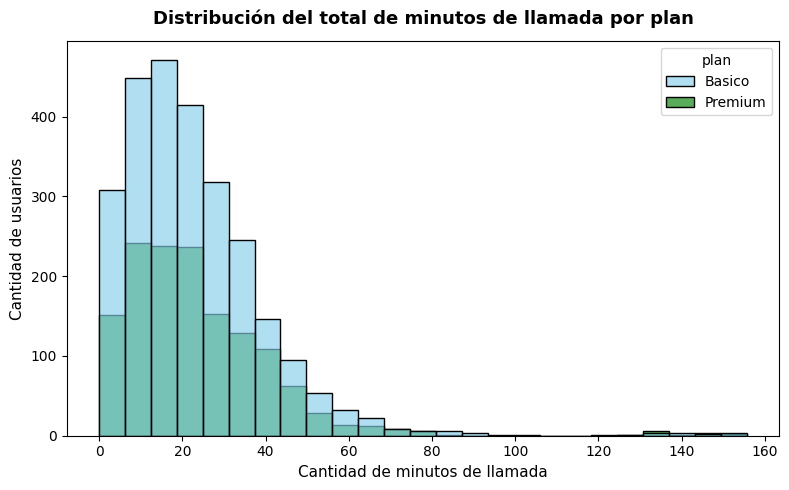

In [39]:

import matplotlib.pyplot as plt
import seaborn as sns

# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
ax = sns.histplot(
    data=user_profile,
    x="cant_minutos_llamada",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=25,
    alpha=0.65,
)

ax.set_title("Distribución del total de minutos de llamada por plan", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Cantidad de minutos de llamada", fontsize=11)
ax.set_ylabel("Cantidad de usuarios", fontsize=11)

plt.tight_layout()
plt.show()


💡Insights: 
cant_minutos_llamada y plan: La distribución de cant_minutos_llamada presenta un sesgo positivo (cola a la derecha) más marcado que las métricas anteriores, concentrando a la mayoría de los usuarios en consumos bajos y moderados (principalmente entre 0 y 40 minutos) y extendiéndose hasta valores cercanos a 155–156 minutos. Tanto Básico como Premium comparten esta misma forma de distribución, diferenciándose principalmente en volumen por la mayor proporción de usuarios del plan Básico.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

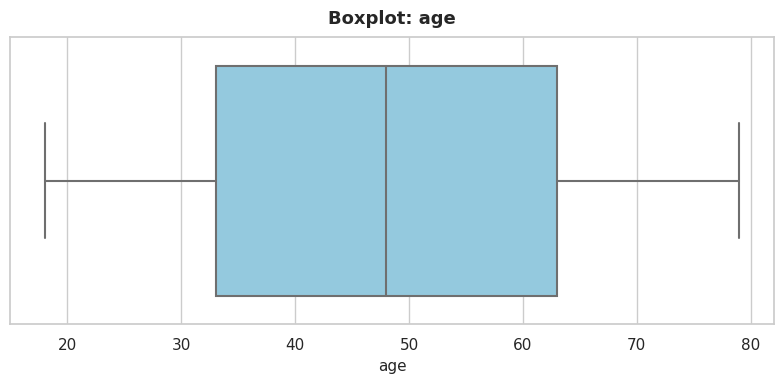

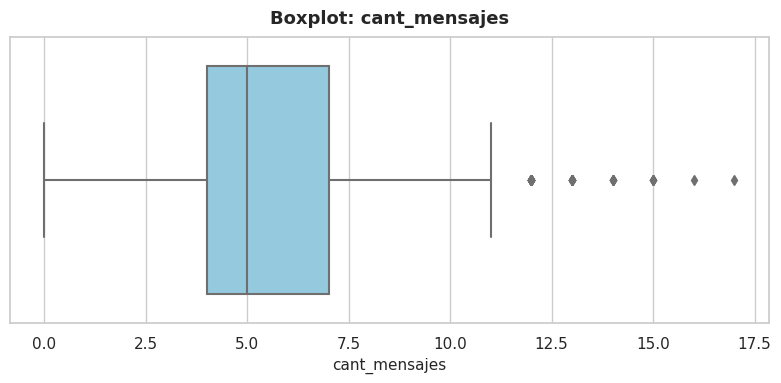

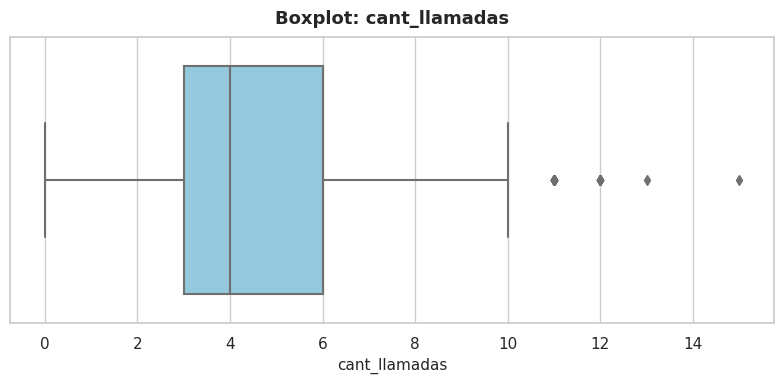

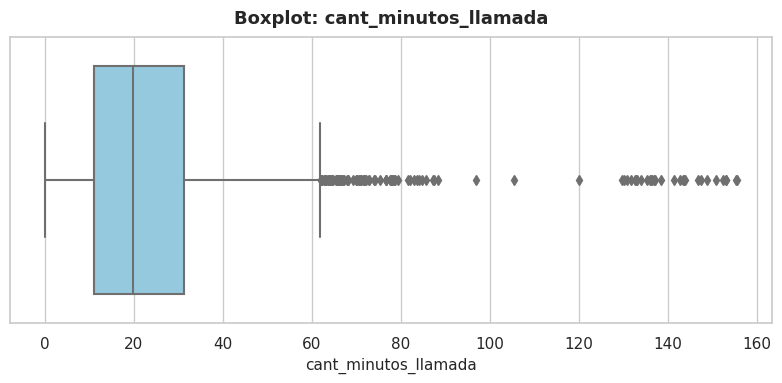

In [40]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Visualizando usando BoxPlot
columnas_numericas = [
    "age",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada",
]

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color="skyblue")
    plt.title(f"Boxplot: {col}", fontsize=13, fontweight="bold", pad=10)
    plt.xlabel(col, fontsize=11)
    plt.tight_layout()
    plt.show()

💡Insights: 

- Boxplot: age — Sin outliers: no aparece ningún punto fuera de los bigotes. La mediana está centrada cerca de 48 años, la caja va aproximadamente de 33 a 63 años, y los bigotes llegan limpiamente desde cerca de 18 hasta 79 años.
- Boxplot: cant_mensajes — Con outliers superiores: hay puntos aislados a la derecha del bigote superior (ubicado alrededor de 11–11.5), extendiéndose aproximadamente desde 12 hasta 17 mensajes. No se ven outliers por debajo del bigote inferior (que llega a 0).
- Boxplot: cant_llamadas — Con outliers superiores: se observan puntos aislados a la derecha del bigote superior (alrededor de 10), en valores cercanos a 11, 12, 13 y 15 llamadas. Tampoco hay outliers en la parte inferior (bigote hasta 0).
- Boxplot: cant_minutos_llamada — Con outliers superiores abundantes y dispersos: es la variable con mayor cola atípica a la derecha. El bigote superior se sitúa cerca de 61–62 minutos, y a partir de ahí se ve una gran cantidad de puntos extremos que llegan hasta cerca de 155–156 minutos.
- 
Sí hay outliers en cant_mensajes, cant_llamadas y cant_minutos_llamada, y en los tres casos están únicamente en el extremo superior (lado derecho) y no hay outliers en age.

In [41]:
import pandas as pd

# Calcular límites con el método IQR para las columnas con outliers superiores
columnas_limites = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

resultados_iqr = []

for col in columnas_limites:
  q1 = user_profile[col].quantile(0.25)
  q3 = user_profile[col].quantile(0.75)
  iqr = q3 - q1

  # Como los outliers están únicamente en el extremo superior, calculamos el límite superior
  limite_superior = q3 + 1.5 * iqr
  cantidad_outliers = (user_profile[col] > limite_superior).sum()
  porcentaje_outliers = (cantidad_outliers / len(user_profile)) * 100

  resultados_iqr.append({
      "columna": col,
      "Q1": round(q1, 2),
      "Q3": round(q3, 2),
      "IQR": round(iqr, 2),
      "limite_superior": round(limite_superior, 2),
      "n_outliers": int(cantidad_outliers),
      "pct_outliers": round(porcentaje_outliers, 2),
  })

df_iqr = pd.DataFrame(resultados_iqr)
df_iqr

,columna,Q1,Q3,IQR,limite_superior,n_outliers,pct_outliers
0,cant_mensajes,4.00,7.00,3.0,11.50,46,1.15
1,cant_llamadas,3.00,6.00,3.0,10.50,30,0.75
2,cant_minutos_llamada,11.11,31.41,20.3,61.87,109,2.72


In [42]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
print(user_profile[columnas_limites].describe())

# Tabla comparativa directa entre límite superior IQR y valor máximo (max)
comparacion_outliers = df_iqr[["columna", "limite_superior", "n_outliers", "pct_outliers"]].copy()
comparacion_outliers["max_real"] = comparacion_outliers["columna"].map(
    lambda col: round(user_profile[col].max(), 2)
)
comparacion_outliers["exceso_sobre_limite"] = (
    comparacion_outliers["max_real"] - comparacion_outliers["limite_superior"]
).round(2)

comparacion_outliers


       cant_mensajes  cant_llamadas  cant_minutos_llamada
count    4000.000000    4000.000000           4000.000000
mean        5.523000       4.477000             23.311225
std         2.359738       2.145139             18.169564
min         0.000000       0.000000              0.000000
25%         4.000000       3.000000             11.107500
50%         5.000000       4.000000             19.780000
75%         7.000000       6.000000             31.412500
max        17.000000      15.000000            155.690000


,columna,limite_superior,n_outliers,pct_outliers,max_real,exceso_sobre_limite
0,cant_mensajes,11.50,46,1.15,17.00,5.50
1,cant_llamadas,10.50,30,0.75,15.00,4.50
2,cant_minutos_llamada,61.87,109,2.72,155.69,93.82


💡Insights: 

Decisión sobre outliers: Tras comparar los límites superiores del método IQR (11.50 en cant_mensajes, 10.50 en cant_llamadas y 61.87 en cant_minutos_llamada) frente a sus valores máximos (17.00, 15.00 y 155.69, respectivamente), se decide mantener los outliers (46 casos / 1.15%, 30 casos / 0.75% y 109 casos / 2.72% sobre 4,000 usuarios). Se trata de valores plausibles asociados a usuarios de mayor uso y no a errores de registro; al analizar las métricas, se complementa la media con la mediana y el IQR debido al sesgo positivo (especialmente en cant_minutos_llamada).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [44]:

import numpy as np
import pandas as pd

# Crear columna grupo_uso
condiciones_uso = [
    (user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5),
    (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10),
]

categorias_uso = ["Bajo uso", "Uso medio"]

user_profile["grupo_uso"] = np.select(
    condiciones_uso, categorias_uso, default="Alto uso"
)

# Verificar distribución de grupo_uso
df_grupo_uso = pd.DataFrame({
    "usuarios": user_profile["grupo_uso"].value_counts(),
    "porcentaje (%)": (
        user_profile["grupo_uso"].value_counts(normalize=True) * 100
    ).round(2),
})

df_grupo_uso


,usuarios,porcentaje (%)
Uso medio,2943,73.58
Bajo uso,779,19.48
Alto uso,278,6.95


In [45]:

# Comprobación rápida de valores únicos y ausencia de nulos en grupo_uso
print("Valores únicos:", user_profile["grupo_uso"].unique())
print("Nulos en grupo_uso:", user_profile["grupo_uso"].isna().sum())

Valores únicos: ['Uso medio' 'Alto uso' 'Bajo uso']
Nulos en grupo_uso: 0


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [48]:
import numpy as np
import pandas as pd

# Crear columna grupo_edad
condiciones_edad = [
    user_profile["age"] < 30,
    user_profile["age"] < 60,
]

categorias_edad = ["Joven", "Adulto"]

user_profile["grupo_edad"] = np.select(
    condiciones_edad, categorias_edad, default="Adulto Mayor"
)

# Revisar distribución de grupo_edad
df_grupo_edad = pd.DataFrame({
    "usuarios": user_profile["grupo_edad"].value_counts(),
    "porcentaje (%)": (
        user_profile["grupo_edad"].value_counts(normalize=True) * 100
    ).round(2),
})

df_grupo_edad

,usuarios,porcentaje (%)
Adulto,2018,50.45
Adulto Mayor,1222,30.55
Joven,760,19.00


In [49]:
print(user_profile[["age", "grupo_edad", "cant_llamadas", "cant_mensajes", "grupo_uso"]].head())
print("\nNulos por columna nueva:\n", user_profile[["grupo_uso", "grupo_edad"]].isna().sum())


    age    grupo_edad  cant_llamadas  cant_mensajes  grupo_uso
0  38.0        Adulto              3              7  Uso medio
1  53.0        Adulto             10              5   Alto uso
2  57.0        Adulto              2              5  Uso medio
3  69.0  Adulto Mayor              3             11   Alto uso
4  63.0  Adulto Mayor              3              4   Bajo uso

Nulos por columna nueva:
 grupo_uso     0
grupo_edad    0
dtype: int64


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

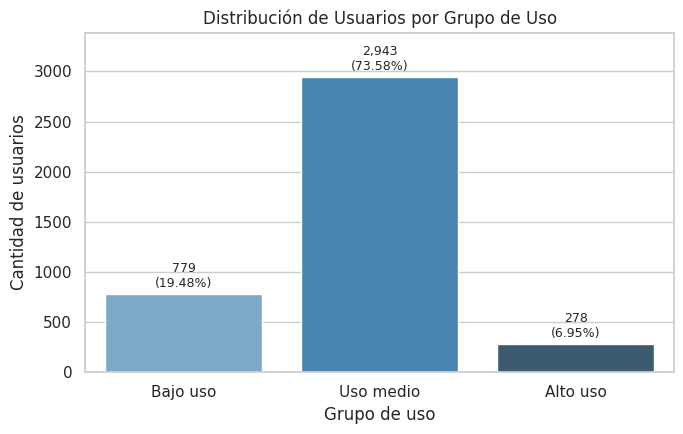

In [50]:

import matplotlib.pyplot as plt
import seaborn as sns

# Visualización de los segmentos por uso
orden_uso = ["Bajo uso", "Uso medio", "Alto uso"]

plt.figure(figsize=(7, 4.5))
ax = sns.countplot(
    data=user_profile, x="grupo_uso", order=orden_uso, palette="Blues_d"
)

ax.set_title("Distribución de Usuarios por Grupo de Uso")
ax.set_xlabel("Grupo de uso")
ax.set_ylabel("Cantidad de usuarios")
ax.set_ylim(0, user_profile["grupo_uso"].value_counts().max() * 1.15)

for p in ax.patches:
  conteo = int(p.get_height())
  pct = (conteo / len(user_profile)) * 100
  ax.annotate(
      f"{conteo:,}\n({pct:.2f}%)",
      (p.get_x() + p.get_width() / 2, conteo),
      ha="center",
      va="bottom",
      xytext=(0, 3),
      textcoords="offset points",
      fontsize=9,
  )

plt.tight_layout()
plt.show()


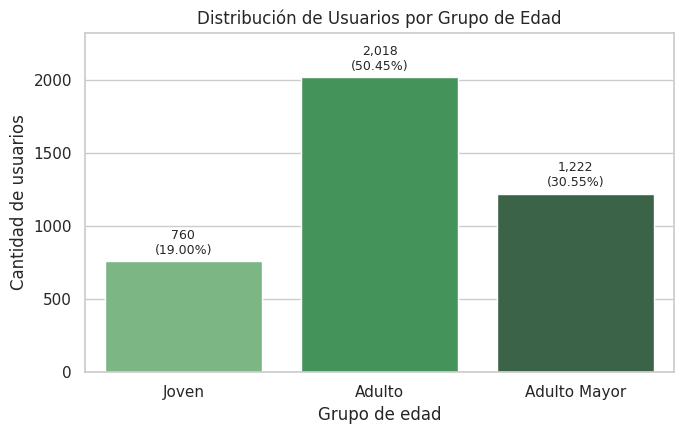

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualización de los segmentos por edad
orden_edad = ["Joven", "Adulto", "Adulto Mayor"]

plt.figure(figsize=(7, 4.5))
ax = sns.countplot(
    data=user_profile, x="grupo_edad", order=orden_edad, palette="Greens_d"
)

ax.set_title("Distribución de Usuarios por Grupo de Edad")
ax.set_xlabel("Grupo de edad")
ax.set_ylabel("Cantidad de usuarios")
ax.set_ylim(0, user_profile["grupo_edad"].value_counts().max() * 1.15)

for p in ax.patches:
  conteo = int(p.get_height())
  pct = (conteo / len(user_profile)) * 100
  ax.annotate(
      f"{conteo:,}\n({pct:.2f}%)",
      (p.get_x() + p.get_width() / 2, conteo),
      ha="center",
      va="bottom",
      xytext=(0, 3),
      textcoords="offset points",
      fontsize=9,
  )

plt.tight_layout()
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

Duplicados y rangos numéricos: sobre los 4,000 registros de user_profile se encontraron 0 filas duplicadas (0.00%). En las variables numéricas, los valores mínimos y máximos son coherentes (age de 18.0 a 79.0, mediana 48.0; cant_mensajes de 0.0 a 17.0, mediana 5.0; cant_llamadas de 0.0 a 15.0, mediana 4.0; y cant_minutos_llamada de 0.0 a 155.69, mediana 19.78), sin valores negativos ni errores de captura evidentes.

Valores nulos en columnas específicas:

-churn_date: 3,534 filas nulas (88.35% de los 4,000 usuarios). Esto suele reflejar usuarios que aún no han cancelado o que permanecen activos, por lo que no debe interpretarse automáticamente como error sin validar la lógica del campo.
-city: 565 filas nulas (14.12%), lo que limita la segmentación geográfica exacta en esa porción de la base.
-reg_date: 40 filas nulas (1.00%), un impacto reducido en la antigüedad o fecha de registro.

🔍 **Segmentos por Edad**

El análisis de grupo_uso y grupo_edad se realizó de forma independiente sobre los 4,000 usuarios de user_profile (sin cruce directo entre ambas variables en este análisis):   

-Por nivel de uso (grupo_uso):
  Uso medio: 2,943 usuarios (73.58%), concentrando la mayor parte de la base con un nivel de actividad intermedio.
  Bajo uso: 779 usuarios (19.48%), con un volumen reducido de actividad.
  Alto uso: 278 usuarios (6.95%), el grupo más pequeño en cantidad de clientes, pero con mayor intensidad de uso.
-Por tramo etario (grupo_edad):   
  Adulto: 2,018 usuarios (50.45%), representando poco más de la mitad de la población.   
  Adulto Mayor: 1,222 usuarios (30.55%), cerca de un tercio del total de usuarios.   
  Joven: 760 usuarios (19.00%), el segmento con menor participación porcentual.   
  
Lectura general: vistas en conjunto, ambas dimensiones muestran que la base de clientes es mayoritariamente adulta y de uso medio.

📊 **Segmentos por Nivel de Uso**

Segmentos más valiosos para ConnectaTel

-Núcleo de volumen y estabilidad — Uso medio (73.58%) y Adulto (50.45%): al agrupar la mayor parte de los usuarios, sostienen el volumen principal del negocio y ofrecen una base sólida para fidelización y mejoras incrementales de plan.
-Nicho de alta intensidad — Alto uso (6.95%): aunque es el grupo más reducido por nivel de uso, su mayor demanda de interacción lo hace clave para planes superiores o complementos de alto consumo.   
-Base madura de peso relevante — Adulto Mayor (30.55%): por su tamaño dentro del total, cuidar su experiencia y claridad tarifaria ayuda a prevenir bajas de servicio.   


**Patrones de uso extremo**

Comportamiento detectado: en cant_mensajes, cant_llamadas y cant_minutos_llamada existen valores extremos altos (que representan entre 0.75% y 2.72% del dataset), asociados a usuarios con picos altos de consumo reales (como un máximo de 155.69 minutos de llamada frente a una mediana de 19.78).

Implicación para el negocio: al conservarlos como casos válidos de alto uso, ConnectaTel puede identificar a los clientes más intensivos para ofrecerles planes acordes a su consumo y evitar que enfrenten cargos inesperados o frustración por límites insuficientes.

💡 **Recomendaciones**
Recomendaciones para mejorar o crear planes:

Plan Estándar / Equilibrado (Uso medio y Adulto): estructurar una oferta clara y competitiva pensada para el consumo intermedio habitual (con mediana de 4 llamadas, 19.78 minutos y 5 mensajes), enfocada en retención y beneficios recurrentes para el 73.58% de la base.
Plan Intensivo / Power User (Alto uso y outliers de alto consumo): crear un plan o paquete adicional con mayor volumen de minutos, llamadas y mensajes y reglas transparentes de excedentes, capitalizando el alto consumo del 6.95% (278 usuarios) y de los outliers activos.
Plan Esencial / Sencillo (Bajo uso y Adulto Mayor): diseñar un plan accesible y sin complicaciones para quienes tienen bajo consumo (779 usuarios, 19.48%) o prefieren propuestas directas (Adulto Mayor, 1,222 usuarios, 30.55%), ayudando a mantenerlos activos dentro de la compañía.  

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link GITHUB: https://github.com/JuanCamilo-DA/ConnectaTel-Analysis